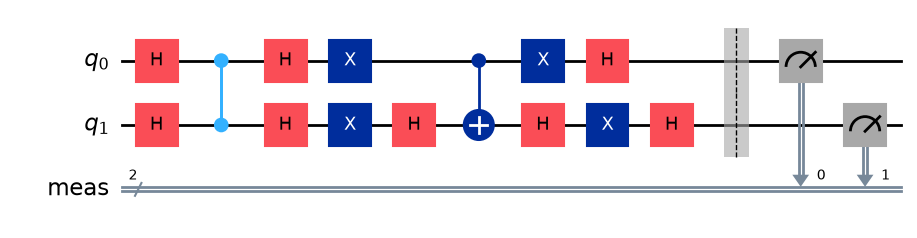

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# ==========================================
# 1. Create circuit
# ==========================================

qc = QuantumCircuit(2)

# ==========================================
# 2. Create superposition
# ==========================================

qc.h(0)
qc.h(1)

# ==========================================
# 3. SAT ORACLE
#
# SAT problem:
#     A AND B
#
# Only |11> satisfies it.
#
# CZ applies a phase flip to |11>.
# ==========================================

qc.cz(0, 1)

# ==========================================
# 4. Grover diffuser
# ==========================================

qc.h(0)
qc.h(1)

qc.x(0)
qc.x(1)

qc.h(1)
qc.cx(0, 1)
qc.h(1)

qc.x(0)
qc.x(1)

qc.h(0)
qc.h(1)

# ==========================================
# 5. Measurement
# ==========================================

qc.measure_all()

qc.draw("mpl")



Counts:
{'11': 9852, '01': 64, '00': 8, '10': 76}


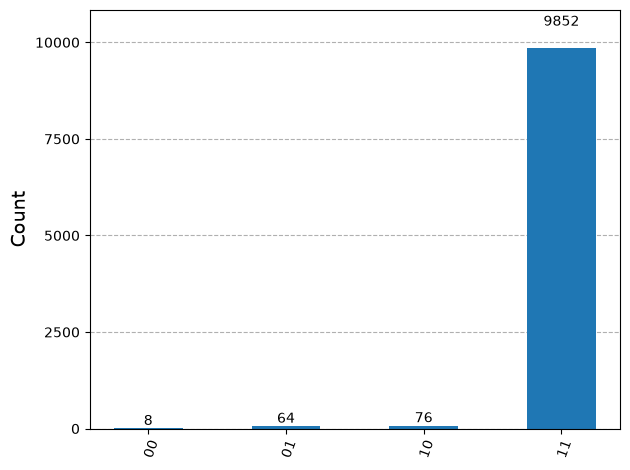

In [7]:
# ==========================================
# 6. Simulator
# ==========================================

service = QiskitRuntimeService()

backend = service.backend(name="ibm_fez")

# ==========================================
# 7. Sampler
# ==========================================

simulator = AerSimulator.from_backend(backend)
shots = 10_000

optimized = transpile(
        qc,
        backend=simulator,
        optimization_level=3,
        seed_transpiler=42
    )

result = simulator.run(
        optimized,
        shots=shots
    ).result()

counts = result.get_counts()

# ==========================================
# 8. Get results
# ==========================================

print("Counts:")
print(counts)

# ==========================================
# 9. Display histogram
# ==========================================

plot_histogram(counts)